Stroke risk prediction dataset using machine learning

Introduction
This project aims to predict the risk of stroke in individuals using machine learning techniques. By leveraging a combination of demographic, lifestyle, and health-related features, the model provides insights that could assist healthcare professionals in early detection and prevention strategies.

Dataset
The dataset used in this project is publicly available and contains information about patients' demographics, medical history, and lifestyle choices. It can be found at:

https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset?resource=download

Note: The dataset is imbalanced, with a small percentage of patients having experienced a stroke. It is also a small dataset.

After running the script, you will obtain:

Best Parameters for each model after hyperparameter tuning.
Classification Report: Precision, Recall, F1-Score for each class.
Confusion Matrix: Visual representation of the model's performance.
ROC-AUC Curve: Plot showing the trade-off between True Positive Rate and False Positive Rate.

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score, learning_curve
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve, average_precision_score
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
df = pd.read_csv("/content/stroke_risk_dataset.csv")

#Show dataset has loaded, search for missing values
print(df.head())
print("\nMissing values per column:")
print(df.isnull().sum())

   Chest Pain  Shortness of Breath  Irregular Heartbeat  Fatigue & Weakness  \
0           0                    1                    1                   1   
1           0                    0                    1                   0   
2           1                    0                    0                   1   
3           1                    0                    1                   1   
4           0                    0                    1                   0   

   Dizziness  Swelling (Edema)  Pain in Neck/Jaw/Shoulder/Back  \
0          0                 0                               0   
1          0                 1                               0   
2          1                 1                               0   
3          0                 1                               1   
4          0                 1                               0   

   Excessive Sweating  Persistent Cough  Nausea/Vomiting  High Blood Pressure  \
0                   1                 1        

In [ ]:
df.head()

,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Age,Stroke Risk (%),At Risk (Binary)
0,0,1,1,1,0,0,0,1,1,1,0,1,1,0,0,54,58.0,1
1,0,0,1,0,0,1,0,0,0,0,1,0,1,1,0,49,40.5,0
2,1,0,0,1,1,1,0,0,1,0,0,0,0,1,0,62,52.0,1
3,1,0,1,1,0,1,1,1,1,1,1,0,0,0,0,48,60.0,1
4,0,0,1,0,0,1,0,1,0,1,1,0,0,1,1,61,56.5,1


In [ ]:
# # Impute missing values in 'bmi' with mean
# df['bmi'].fillna(df['bmi'].mean(), inplace=True)
# print(df.isnull().sum())


In [ ]:
# # Encode categorical variables
# le = LabelEncoder()
# categorical_features = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
# for feature in categorical_features:
#     df[feature] = le.fit_transform(df[feature])


In [ ]:
# # Drop 'id' column
# df.drop('id', axis=1, inplace=True)

In [ ]:
df.columns

Index(['Chest Pain', 'Shortness of Breath', 'Irregular Heartbeat',
       'Fatigue & Weakness', 'Dizziness', 'Swelling (Edema)',
       'Pain in Neck/Jaw/Shoulder/Back', 'Excessive Sweating',
       'Persistent Cough', 'Nausea/Vomiting', 'High Blood Pressure',
       'Chest Discomfort (Activity)', 'Cold Hands/Feet', 'Snoring/Sleep Apnea',
       'Anxiety/Feeling of Doom', 'Age', 'Stroke Risk (%)',
       'At Risk (Binary)'],
      dtype='object')

In [ ]:
def handle_binary_missing(df, binary_cols, imputation_method='mode'):
    """
    Handle missing values for binary columns using specified imputation method.
    """

    for col in binary_cols:
        if imputation_method == 'mode':
            mode_value = df[col].mode()[0]
            df[col] = df[col].fillna(mode_value)
            print(f"🔹 Imputed missing values in binary column '{col}' with mode: {mode_value}")
        elif imputation_method == 'mean':
            mean_value = df[col].mean()
            df[col] = df[col].fillna(mean_value)
            print(f"🔹 Imputed missing values in binary column '{col}' with mean: {mean_value}")

    return df

In [ ]:
def handle_categorical_missing(df, categorical_cols, imputation_method='mode'):
    """
    Handle missing values for categorical columns using specified imputation method.
    """

    for col in categorical_cols:
        if imputation_method == 'mode':
            mode_value = df[col].mode()[0]
            df[col] = df[col].fillna(mode_value)
            print(f"🔹 Imputed missing values in categorical column '{col}' with mode: {mode_value}")
        elif imputation_method == 'most_frequent':
            most_frequent_value = df[col].value_counts().idxmax()
            df[col] = df[col].fillna(most_frequent_value)
            print(f"🔹 Imputed missing values in categorical column '{col}' with most frequent: {most_frequent_value}")

    return df

In [ ]:
def handle_numerical_missing(df, numerical_cols, imputation_method='median'):
    """
    Handle missing values for numerical columns using specified imputation method.
    """

    for col in numerical_cols:
        if df[col].dtype in ['int64', 'float64']:
            if imputation_method == 'mean':
                mean_value = df[col].mean()
                df[col] = df[col].fillna(mean_value)
                print(f"🔹 Imputed missing values in numerical column '{col}' with mean: {mean_value}")
            elif imputation_method == 'median':
                median_value = df[col].median()
                df[col] = df[col].fillna(median_value)
                print(f"🔹 Imputed missing values in numerical column '{col}' with median: {median_value}")
            elif imputation_method == 'most_frequent':
                most_frequent_value = df[col].value_counts().idxmax()
                df[col] = df[col].fillna(most_frequent_value)
                print(f"🔹 Imputed missing values in numerical column '{col}' with most frequent: {most_frequent_value}")

    return df

In [ ]:
def handle_multivariate_imputation(df, imputation_method='knn'):
    """
    Handle multivariate imputation using KNN or Iterative Imputer.
    """

    if imputation_method == 'knn':
        print("🔹 Applying KNN Imputer...")
        knn_imputer = KNNImputer(n_neighbors=5)
        df_imputed = pd.DataFrame(knn_imputer.fit_transform(df), columns=df.columns)
        print("🔹 KNN Imputation applied.")
    else:
        print("❌ Invalid multivariate imputation method chosen.")
        return df

    return df_imputed

In [ ]:
def handle_fill(df, fill_method='forward'):
    """
    Handle missing values using forward or backward fill.
    """

    if fill_method == 'forward':
        print("🔹 Applying forward fill...")
        df.fillna(method='ffill', inplace=True)
        print("🔹 Forward fill applied successfully.")
    elif fill_method == 'backward':
        print("🔹 Applying backward fill...")
        df.fillna(method='bfill', inplace=True)
        print("🔹 Backward fill applied successfully.")
    else:
        print("❌ Invalid fill method chosen.")

    return df

In [ ]:
def classify_columns(df):
    """
    Classify columns into binary, numerical, and categorical types.
    """
    binary_cols = []
    numerical_cols = []
    categorical_cols = []

    for col in df.columns:
        if df[col].dtype in ['int64', 'float64']:
            if df[col].nunique() == 2:
                binary_cols.append(col)
            else:
                numerical_cols.append(col)
        elif df[col].dtype == 'object' or df[col].dtype.name == 'category':
            if df[col].nunique() == 2:
                binary_cols.append(col)
            else:
                categorical_cols.append(col)

    return {
        'binary': binary_cols,
        'numerical': numerical_cols,
        'categorical': categorical_cols
    }

In [ ]:
classify_columns(df)

{'binary': ['Chest Pain',
  'Shortness of Breath',
  'Irregular Heartbeat',
  'Fatigue & Weakness',
  'Dizziness',
  'Swelling (Edema)',
  'Pain in Neck/Jaw/Shoulder/Back',
  'Excessive Sweating',
  'Persistent Cough',
  'Nausea/Vomiting',
  'High Blood Pressure',
  'Chest Discomfort (Activity)',
  'Cold Hands/Feet',
  'Snoring/Sleep Apnea',
  'Anxiety/Feeling of Doom',
  'At Risk (Binary)'],
 'numerical': ['Age', 'Stroke Risk (%)'],
 'categorical': []}

In [ ]:
def filter_columns_by_null_percentage(df, column_classification, threshold=0.1):
    """
    Filters out columns from the classification lists that have more than the specified threshold of missing values.
    """
    filtered_classification = {'binary': [], 'numerical': [], 'categorical': []}
    missing_percentage = df.isnull().mean()

    for col_type in column_classification:
        for col in column_classification[col_type]:
            if missing_percentage[col] <= threshold:
                filtered_classification[col_type].append(col)
            else:
                print(f"🔹 Column '{col}' has more than {threshold*100}% missing values and is removed.")

    return filtered_classification

In [ ]:
column_classification = {
    'binary': ['Chest Pain',
  'Shortness of Breath',
  'Irregular Heartbeat',
  'Fatigue & Weakness',
  'Dizziness',
  'Swelling (Edema)',
  'Pain in Neck/Jaw/Shoulder/Back',
  'Excessive Sweating',
  'Persistent Cough',
  'Nausea/Vomiting',
  'High Blood Pressure',
  'Chest Discomfort (Activity)',
  'Cold Hands/Feet',
  'Snoring/Sleep Apnea',
  'Anxiety/Feeling of Doom',
  'At Risk (Binary)'],
 'numerical': ['Age', 'Stroke Risk (%)'],
 'categorical': []
}

filtered_classification = filter_columns_by_null_percentage(df, column_classification, threshold=0.1)
print(filtered_classification)

{'binary': ['Chest Pain', 'Shortness of Breath', 'Irregular Heartbeat', 'Fatigue & Weakness', 'Dizziness', 'Swelling (Edema)', 'Pain in Neck/Jaw/Shoulder/Back', 'Excessive Sweating', 'Persistent Cough', 'Nausea/Vomiting', 'High Blood Pressure', 'Chest Discomfort (Activity)', 'Cold Hands/Feet', 'Snoring/Sleep Apnea', 'Anxiety/Feeling of Doom', 'At Risk (Binary)'], 'numerical': ['Age', 'Stroke Risk (%)'], 'categorical': []}


In [ ]:
handle_binary_missing(df, filtered_classification["binary"], imputation_method='mode')

🔹 Imputed missing values in binary column 'Chest Pain' with mode: 1
🔹 Imputed missing values in binary column 'Shortness of Breath' with mode: 0
🔹 Imputed missing values in binary column 'Irregular Heartbeat' with mode: 0
🔹 Imputed missing values in binary column 'Fatigue & Weakness' with mode: 1
🔹 Imputed missing values in binary column 'Dizziness' with mode: 1
🔹 Imputed missing values in binary column 'Swelling (Edema)' with mode: 1
🔹 Imputed missing values in binary column 'Pain in Neck/Jaw/Shoulder/Back' with mode: 0
🔹 Imputed missing values in binary column 'Excessive Sweating' with mode: 1
🔹 Imputed missing values in binary column 'Persistent Cough' with mode: 1
🔹 Imputed missing values in binary column 'Nausea/Vomiting' with mode: 1
🔹 Imputed missing values in binary column 'High Blood Pressure' with mode: 1
🔹 Imputed missing values in binary column 'Chest Discomfort (Activity)' with mode: 0
🔹 Imputed missing values in binary column 'Cold Hands/Feet' with mode: 0
🔹 Imputed missi

,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Age,Stroke Risk (%),At Risk (Binary)
0,0,1,1,1,0,0,0,1,1,1,0,1,1,0,0,54,58.0,1
1,0,0,1,0,0,1,0,0,0,0,1,0,1,1,0,49,40.5,0
2,1,0,0,1,1,1,0,0,1,0,0,0,0,1,0,62,52.0,1
3,1,0,1,1,0,1,1,1,1,1,1,0,0,0,0,48,60.0,1
4,0,0,1,0,0,1,0,1,0,1,1,0,0,1,1,61,56.5,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,1,0,0,0,0,0,0,1,0,1,1,1,0,0,1,18,30.0,0
69996,0,0,0,1,0,1,0,1,0,0,0,1,1,1,0,24,33.0,0
69997,1,1,0,1,1,1,0,0,0,0,1,0,0,0,0,49,45.5,0
69998,0,1,1,1,1,0,0,0,0,0,0,1,1,1,0,45,48.5,0


In [ ]:
handle_numerical_missing(df, filtered_classification["numerical"], imputation_method='most_frequent')

🔹 Imputed missing values in numerical column 'Age' with most frequent: 37
🔹 Imputed missing values in numerical column 'Stroke Risk (%)' with most frequent: 56.0


,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Age,Stroke Risk (%),At Risk (Binary)
0,0,1,1,1,0,0,0,1,1,1,0,1,1,0,0,54,58.0,1
1,0,0,1,0,0,1,0,0,0,0,1,0,1,1,0,49,40.5,0
2,1,0,0,1,1,1,0,0,1,0,0,0,0,1,0,62,52.0,1
3,1,0,1,1,0,1,1,1,1,1,1,0,0,0,0,48,60.0,1
4,0,0,1,0,0,1,0,1,0,1,1,0,0,1,1,61,56.5,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,1,0,0,0,0,0,0,1,0,1,1,1,0,0,1,18,30.0,0
69996,0,0,0,1,0,1,0,1,0,0,0,1,1,1,0,24,33.0,0
69997,1,1,0,1,1,1,0,0,0,0,1,0,0,0,0,49,45.5,0
69998,0,1,1,1,1,0,0,0,0,0,0,1,1,1,0,45,48.5,0


In [ ]:
df['At Risk (Binary)'].value_counts()/len(df)

,count
At Risk (Binary),
1,0.6492
0,0.3508


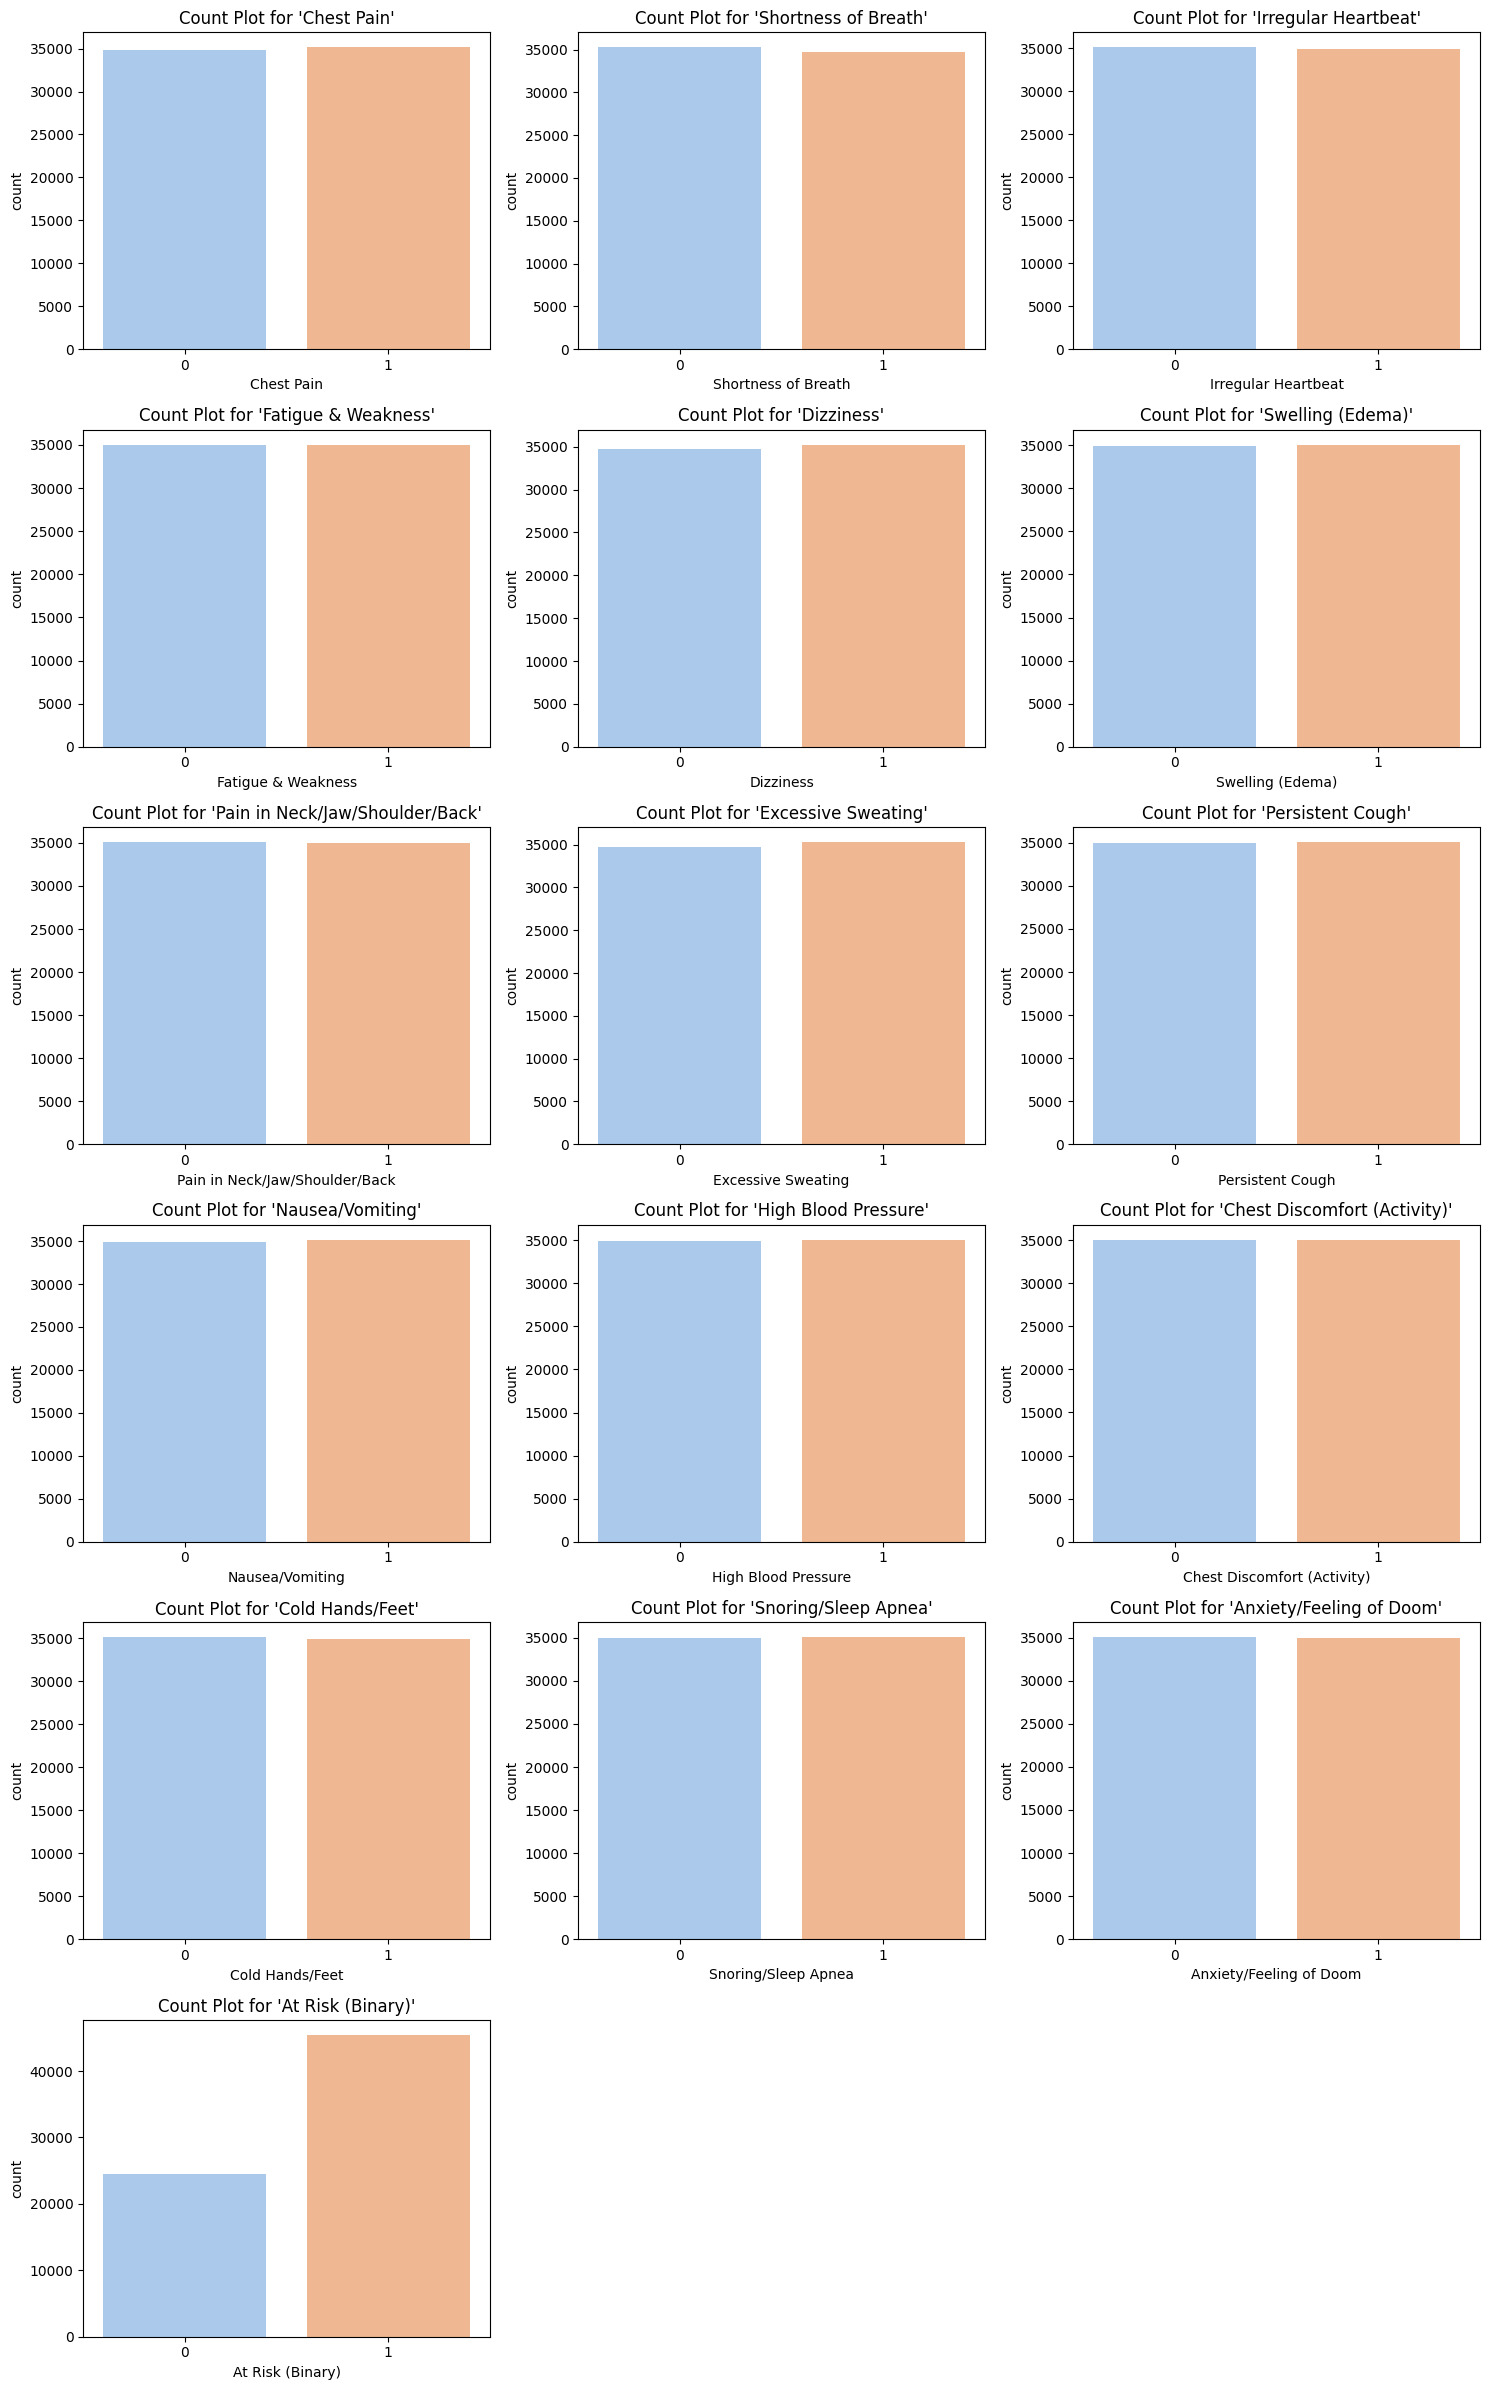

In [ ]:


# Select binary columns (only those with 2 unique values: 0 and 1)
binary_cols = [col for col in df.columns if df[col].nunique() == 2 and df[col].dtype in ['int64', 'float64']]

# Plot count plots for each binary feature
num_plots = len(binary_cols)
num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 4))
axes = axes.flatten()

for i, col in enumerate(binary_cols):
    sns.countplot(x=col, data=df, ax=axes[i], palette='pastel')
    axes[i].set_title(f"Count Plot for '{col}'")
    axes[i].set_xticks([0, 1])

# Hide unused subplots if any
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [ ]:
def plot_binary_countplots(df, binary_cols):
    """Plot count plots for binary features to visualize 0/1 distributions."""
    num_plots = len(binary_cols)
    num_rows = (num_plots // 3) + (1 if num_plots % 3 != 0 else 0)

    fig, axes = plt.subplots(num_rows, 3, figsize=(15, num_rows * 5))
    axes = axes.flatten()

    for i, col in enumerate(binary_cols):
        sns.countplot(x=col, data=df, palette='pastel', ax=axes[i])
        axes[i].set_title(f"Count Plot of {col}")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Count")

    for j in range(num_plots, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()


In [ ]:
def remove_outliers(df, numerical_cols, method="IQR"):
    """Remove rows containing outliers from numerical columns using IQR or Z-score."""
    df_clean = df.copy()

    for col in numerical_cols:
        if method == "IQR":
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
        elif method == "Z-score":
            mean = df[col].mean()
            std_dev = df[col].std()
            df_clean = df_clean[(np.abs((df[col] - mean) / std_dev) < 3)]

        print(f"🔹 Outliers removed in column '{col}' using {method} method.")

    return df_clean

In [ ]:
def remove_outliers(df, numerical_cols, method="IQR"):
    """Remove rows containing outliers from non-binary numerical columns using IQR or Z-score."""
    df_clean = df.copy()

    for col in numerical_cols:
        unique_vals = df[col].dropna().unique()
        if len(unique_vals) <= 2 and set(unique_vals).issubset({0, 1}):
            print(f"⏭️ Skipping binary column '{col}' (only 0 and 1).")
            continue

        if method == "IQR":
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
        elif method == "Z-score":
            mean = df[col].mean()
            std_dev = df[col].std()
            df_clean = df_clean[(np.abs((df[col] - mean) / std_dev) < 3)]

        print(f"🔹 Outliers removed in column '{col}' using {method} method.")

    return df_clean


In [ ]:
from scipy.stats.mstats import winsorize
import numpy as np

def transform_outliers(df, numerical_cols, method="winsorize"):
    """Transform outliers in non-binary numerical columns using winsorization, log, or square root transformation."""
    df_transformed = df.copy()

    for col in numerical_cols:
        unique_vals = df[col].dropna().unique()
        if len(unique_vals) <= 2 and set(unique_vals).issubset({0, 1}):
            print(f"⏭️ Skipping binary column '{col}' (only 0 and 1).")
            continue

        if method == "winsorize":
            df_transformed[col] = winsorize(df[col], limits=[0.05, 0.05])
        elif method == "log":
            df_transformed[col] = np.log1p(df[col])
        elif method == "sqrt":
            df_transformed[col] = np.sqrt(df[col])

        print(f"🔹 Outliers in '{col}' transformed using {method} method.")

    return df_transformed


In [ ]:
# Filter out binary columns from the list before passing to transform_outliers
transform_required_columns = ["At Risk (Binary)"]

# Keep only non-binary numeric columns
valid_transform_columns = [col for col in transform_required_columns
                           if df[col].nunique() > 2 or not set(df[col].dropna().unique()).issubset({0, 1})]

# Apply transformation only if there's a valid column
if valid_transform_columns:
    df = transform_outliers(df, valid_transform_columns)
else:
    print("⚠️ No valid non-binary columns to transform.")


⚠️ No valid non-binary columns to transform.


In [ ]:
# Handle imbalanced dataset using SMOTE
# from imblearn.over_sampling import SMOTE
# sm = SMOTE(random_state=42)
# X_res, y_res = sm.fit_resample(X, y)
X = df.drop('At Risk (Binary)', axis=1)
y = df['At Risk (Binary)']

from imblearn.over_sampling import RandomOverSampler

# Create RandomOverSampler instance
ros = RandomOverSampler(random_state=42)
# Apply random oversampling
X_res, y_res = ros.fit_resample(X, y)

In [ ]:
# Split data into training, validation, and testing sets (60% train, 20% validation, 20% test)
X_train_full, X_test, y_train_full, y_test = train_test_split(X_res, y_res, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)


In [ ]:
# # Feature Scaling
# scaler = StandardScaler()
# numerical_features = ['age', 'avg_glucose_level', 'bmi']

# X_train[numerical_features] = scaler.fit_transform(X_train[numerical_features])
# X_val[numerical_features] = scaler.transform(X_val[numerical_features])
# X_test[numerical_features] = scaler.transform(X_test[numerical_features])


In [ ]:
# Install necessary libraries
!pip install -U imbalanced-learn catboost dask[dataframe] shap lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 6.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 63.7 MB/s eta 0:00:00
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=4264990cf9a90cc57640389cb542a25e4e891eb90e3ed80c395f0bd659ec2998
  Stored in directory: /root/.cache/pip/wheels/85/fa/a3/9c2d44c9f3cd77cf4e533b58900b2bf4487f2a17e8ec212a3d
Successfully built lime
  Attempting uninstall: dask
    Found existing installation: dask 2025.5.0
    Uninstalling dask-2025.5.0:
      Successfully uninstalled dask-2025.5.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
rapids-dask-dependency 25.6.0 requires dask==2025.5.0, but you have dask 2025.7.0 which is incompatible.
distribute

In [ ]:
import numpy as np
import pandas as pd
import time
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, mean_absolute_error, mean_squared_error, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from imblearn.over_sampling import RandomOverSampler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import copy # Essential: This line imports the 'copy' module for deepcopy
import matplotlib.pyplot as plt # Added for plotting
import seaborn as sns # Added for plotting
import shap # Added for SHAP (Explainable AI)

In [32]:

def prepare_data(X, y):
    """
    Prepares train/val/test splits with oversampling.
    Applies RandomOverSampler on the minority class to balance the dataset,
    then splits the data into training, validation, and test sets,
    ensuring stratification to maintain class distribution.
    """
    # Initialize RandomOverSampler to balance the minority class
    ros = RandomOverSampler(sampling_strategy='minority', random_state=42)
    # Apply oversampling to the input features (X) and target (y)
    X_res, y_res = ros.fit_resample(X, y)
    print(f"Balanced dataset shape after oversampling: X_res={X_res.shape}, y_res={y_res.shape}")

    # Split the balanced dataset into a full training set and a test set (80/20 split)
    # stratify=y_res ensures that the proportion of target classes is maintained in both splits
    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X_res, y_res, test_size=0.2, random_state=42, stratify=y_res
    )

    # Split the full training set into training and validation sets (75/25 split of train_full, effectively 60/20/20 overall)
    # stratify=y_train_full ensures class distribution is maintained in these splits as well
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=0.25, random_state=42, stratify=y_train_full
    )

    print(f"Training data shape: X_train={X_train.shape}, y_train={y_train.shape}")
    print(f"Validation data shape: X_val={X_val.shape}, y_val={y_val.shape}")
    print(f"Test data shape: X_test={X_test.shape}, y_test={y_test.shape}")
    return X_train, X_val, X_test, X_train_full, y_train, y_val, y_test, y_train_full

In [33]:
models = {
    'RandomForest': {
        'model': RandomForestClassifier(random_state=42, n_jobs=-1),
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [None, 10],
            'min_samples_split': [2, 5]
        }
    },
    'LogisticRegression': {
        'model': Pipeline([('scaler', StandardScaler()),
                           ('lr', LogisticRegression(random_state=42, max_iter=1000))]),
        'params': {
            'lr__C': [0.1, 1, 10],
            'lr__penalty': ['l2'],
            'lr__solver': ['lbfgs']
        }
    },
    # 'MLP': {
    #     'model': Pipeline([('scaler', StandardScaler()),
    #                        ('mlp', MLPClassifier(random_state=42, early_stopping=True))]),
    #     'params': {
    #         'mlp__hidden_layer_sizes': [(50,), (100,)],
    #         'mlp__alpha': [0.0001, 0.001]
    #     }
    # },
    # 'SVM': {
    #     'model': Pipeline([('scaler', StandardScaler()),
    #                        ('svm', SVC(random_state=42, probability=True))]),
    #     'params': {
    #         'svm__C': [0.1, 1, 10],
    #         'svm__kernel': ['linear', 'rbf']
    #     }
    # },
    # 'NaiveBayes': {
    #     'model': GaussianNB(),
    #     'params': {
    #         'var_smoothing': [1e-9, 1e-8]
    #     }
    # },
    'ExtraTrees': {
        'model': ExtraTreesClassifier(random_state=42, n_jobs=-1),
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [None, 10]
        }
    },
    'GradientBoosting': {
        'model': GradientBoostingClassifier(random_state=42),
        'params': {
            'n_estimators': [100],
            'learning_rate': [0.1],
            'max_depth': [3]
        }
    },
    'XGBoost': {
        'model': XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss'),
        'params': {
            'n_estimators': [100],
            'max_depth': [3, 6],
            'learning_rate': [0.1]
        }
    },
    'LightGBM': {
        'model': LGBMClassifier(random_state=42, n_jobs=-1),
        'params': {
            'n_estimators': [100],
            'learning_rate': [0.1],
            'num_leaves': [31]
        }
    },
    'CatBoost': {
        'model': CatBoostClassifier(random_state=42, verbose=0),
        'params': {
            'iterations': [100],
            'learning_rate': [0.1],
            'depth': [6]
        }
    }
}

In [34]:
# Initialize Stratified K-Fold Cross-Validation
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)


In [36]:
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix,
    mean_squared_error, mean_absolute_error
)

# Initialize StratifiedKFold for classification (use KFold for regression)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Dictionary to store model results
model_results = {}

# Loop over each model
for model_name, model_info in models.items():
    print(f"\nTraining and tuning {model_name}...")
    start_time = time.time()

    model = model_info['model']
    param_grid = model_info['params']

    # Hyperparameter tuning with GridSearchCV
    search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring='f1',  # Use 'neg_mean_squared_error' for regression
        cv=skf,
        n_jobs=-1,
        verbose=1
    )
    search.fit(X_train, y_train)
    best_model = search.best_estimator_

    # Initialize lists to store all metrics
    accuracies, precisions, recalls, f1_scores, aucs = [], [], [], [], []
    mse_scores, mae_scores, rmse_scores = [], [], []
    tprs, fprs, specificities, npvs = [], [], [], []

    # Cross-validated evaluation
    for train_idx, val_idx in skf.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        best_model.fit(X_tr, y_tr)
        y_pred = best_model.predict(X_val)

        # Classification metrics
        accuracies.append(accuracy_score(y_val, y_pred))
        precisions.append(precision_score(y_val, y_pred, zero_division=0))
        recalls.append(recall_score(y_val, y_pred, zero_division=0))
        f1_scores.append(f1_score(y_val, y_pred, zero_division=0))

        # Regression metrics (on predicted probabilities)
        if hasattr(best_model, 'predict_proba'):
            y_proba = best_model.predict_proba(X_val)[:, 1]
            aucs.append(roc_auc_score(y_val, y_proba))
            mse_scores.append(mean_squared_error(y_val, y_proba))
            mae_scores.append(mean_absolute_error(y_val, y_proba))
            rmse_scores.append(np.sqrt(mean_squared_error(y_val, y_proba)))
        else:
            aucs.append(np.nan)
            mse_scores.append(np.nan)
            mae_scores.append(np.nan)
            rmse_scores.append(np.nan)

        # Confusion matrix metrics
        cm = confusion_matrix(y_val, y_pred)
        if cm.shape == (2, 2):
            tn, fp, fn, tp = cm.ravel()
            tprs.append(tp / (tp + fn) if (tp + fn) > 0 else 0)
            fprs.append(fp / (fp + tn) if (fp + tn) > 0 else 0)
            specificities.append(tn / (tn + fp) if (tn + fp) > 0 else 0)
            npvs.append(tn / (tn + fn) if (tn + fn) > 0 else 0)
        else:
            tprs.append(np.nan)
            fprs.append(np.nan)
            specificities.append(np.nan)
            npvs.append(np.nan)

    # Store all results
    model_results[model_name] = {
        "Best Params": search.best_params_,
        "Accuracy": np.mean(accuracies),
        "Precision": np.mean(precisions),
        "Recall": np.mean(recalls),
        "F1 Score": np.mean(f1_scores),
        "AUC": np.mean(aucs),
        "MSE (Proba)": np.mean(mse_scores),
        "MAE (Proba)": np.mean(mae_scores),
        "RMSE (Proba)": np.mean(rmse_scores),
        "Specificity": np.mean(specificities),
        "NPV": np.mean(npvs),
        "TPR": np.mean(tprs),
        "FPR": np.mean(fprs),
        "Training Time (s)": time.time() - start_time
    }

    # Print results
    print(f"\n{model_name} Results:")
    for metric, value in model_results[model_name].items():
        if isinstance(value, float):
            print(f"{metric}: {value:.4f}")
        else:
            print(f"{metric}: {value}")

# Convert results to DataFrame
results_df = pd.DataFrame(model_results).T
print("\nFinal Model Comparison:")
print(results_df.sort_values('F1 Score', ascending=False))


Training and tuning RandomForest...
Fitting 5 folds for each of 8 candidates, totalling 40 fits

RandomForest Results:
Best Params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000
AUC: 1.0000
MSE (Proba): 0.0001
MAE (Proba): 0.0044
RMSE (Proba): 0.0107
Specificity: 1.0000
NPV: 1.0000
TPR: 1.0000
FPR: 0.0000
Training Time (s): 78.9594

Training and tuning LogisticRegression...
Fitting 5 folds for each of 3 candidates, totalling 15 fits

LogisticRegression Results:
Best Params: {'lr__C': 10, 'lr__penalty': 'l2', 'lr__solver': 'lbfgs'}
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000
AUC: 1.0000
MSE (Proba): 0.0009
MAE (Proba): 0.0051
RMSE (Proba): 0.0304
Specificity: 1.0000
NPV: 1.0000
TPR: 1.0000
FPR: 0.0000
Training Time (s): 6.0454

Training and tuning ExtraTrees...
Fitting 5 folds for each of 4 candidates, totalling 20 fits

ExtraTrees Results:
Best Params: {'max_depth': None, 'n_es


Model Comparison Results:


,Best Params,Accuracy,Precision,Recall,F1 Score,AUC,MSE (Proba),MAE (Proba),RMSE (Proba),Specificity,NPV,TPR,FPR,Training Time (s)
RandomForest,"{'max_depth': None, 'min_samples_split': 2, 'n...",1.0,1.0,1.0,1.0,1.0,0.000114,0.004403,0.010696,1.0,1.0,1.0,0.0,78.959367
LogisticRegression,"{'lr__C': 10, 'lr__penalty': 'l2', 'lr__solver...",1.0,1.0,1.0,1.0,1.0,0.000928,0.005071,0.030448,1.0,1.0,1.0,0.0,6.045413
ExtraTrees,"{'max_depth': None, 'n_estimators': 200}",0.990904,0.994169,0.987494,0.99082,0.999675,0.015517,0.057386,0.12454,0.994275,0.987722,0.987494,0.005725,117.69487
GradientBoosting,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",1.0,1.0,1.0,1.0,1.0,0.0,0.000022,0.000022,1.0,1.0,1.0,0.0,20.190358
XGBoost,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",1.0,1.0,1.0,1.0,1.0,0.0,0.000052,0.000052,1.0,1.0,1.0,0.0,5.065323
LightGBM,"{'learning_rate': 0.1, 'n_estimators': 100, 'n...",1.0,1.0,1.0,1.0,1.0,0.0,0.000022,0.000022,1.0,1.0,1.0,0.0,12.822082
CatBoost,"{'depth': 6, 'iterations': 100, 'learning_rate...",1.0,1.0,1.0,1.0,1.0,0.0,0.000373,0.000478,1.0,1.0,1.0,0.0,9.885835


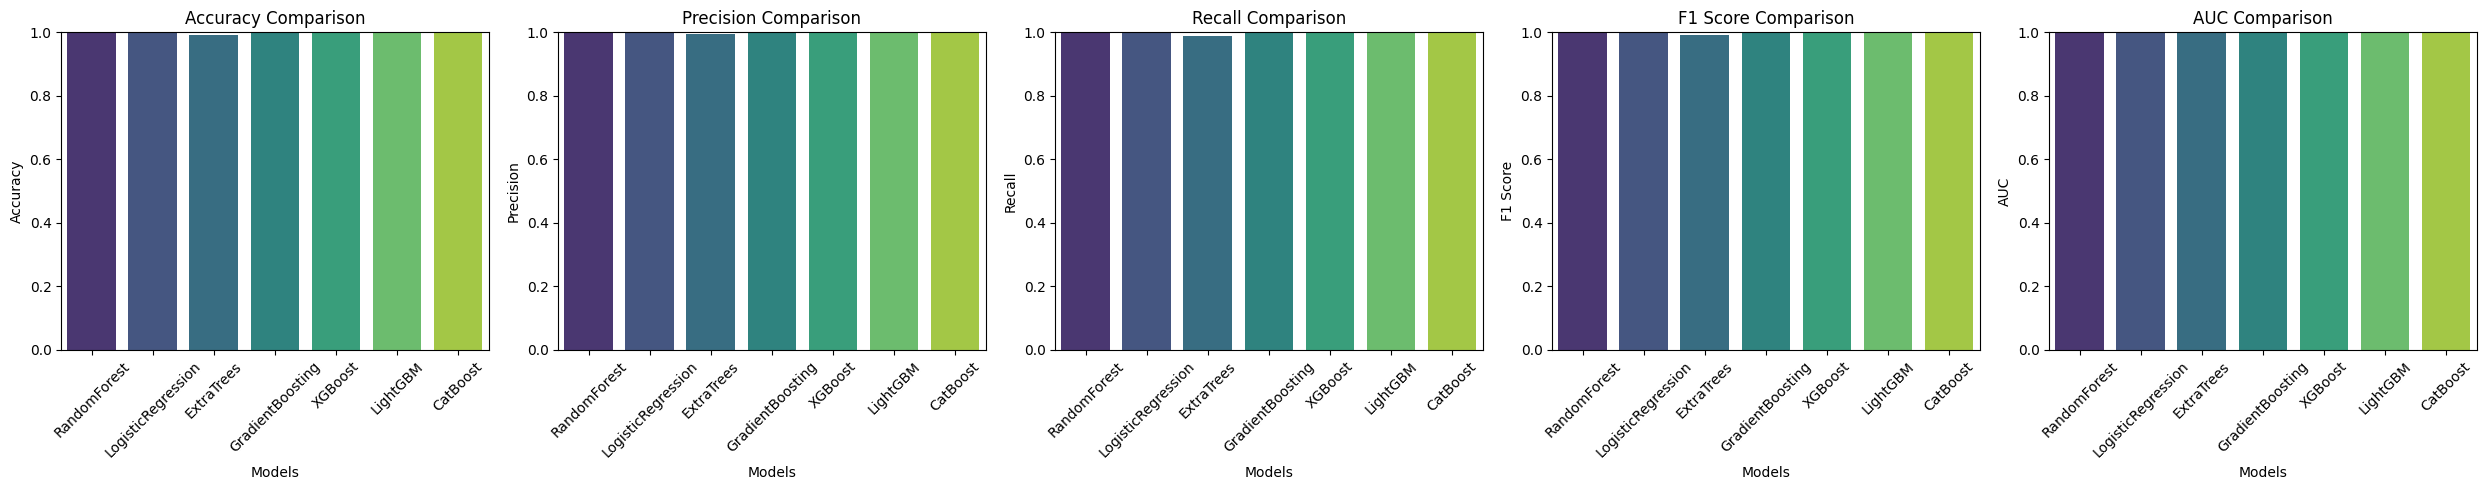

In [37]:
# Convert model results to a DataFrame for comparison
results_df = pd.DataFrame(model_results).T

# Display model performance comparison
print("\nModel Comparison Results:")
display(results_df)

# Plot comparison of each metric across models
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "AUC"]
fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for i, metric in enumerate(metrics):
    sns.barplot(x=results_df.index, y=results_df[metric], ax=axes[i], palette='viridis')
    axes[i].set_title(f"{metric} Comparison")
    axes[i].set_ylim(0, 1)
    axes[i].set_xlabel("Models")
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


In [39]:
from sklearn.ensemble import VotingClassifier

# Select the top 3 models based on F1 Score
top_models = results_df.sort_values(by='F1 Score', ascending=False).head(3).index.tolist()

# Initialize estimators with best parameters
estimators = []
for model_name in top_models:
    # Get the model configuration
    model_config = models[model_name]

    # For pipeline models, we need to set params differently
    if isinstance(model_config['model'], Pipeline):
        # Create new pipeline with best params
        best_params = model_results[model_name]['Best Params']
        model = model_config['model']

        # Set the parameters for the pipeline steps
        for param_name, param_value in best_params.items():
            step_name, param = param_name.split('__', 1)
            for step in model.steps:
                if step[0] == step_name:
                    setattr(step[1], param, param_value)
        estimators.append((model_name, model))
    else:
        # For regular models
        model = model_config['model'].set_params(**model_results[model_name]['Best Params'])
        estimators.append((model_name, model))

# Create VotingClassifier ensemble (soft voting for probability estimates)
ensemble_model = VotingClassifier(
    estimators=estimators,
    voting='soft',
    n_jobs=-1  # Use all available cores
)

# Train ensemble
print("\nTraining ensemble model with top 3 models:")
print(top_models)
start_time = time.time()
ensemble_model.fit(X_train, y_train)
training_time = time.time() - start_time

# Evaluate ensemble model using cross-validation (consistent with individual models)
cv_metrics = {
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1 Score': [],
    'AUC': [],
    'Specificity': [],
    'NPV': [],
    'TPR': [],
    'FPR': []
}

for train_idx, val_idx in skf.split(X_train, y_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    ensemble_model.fit(X_tr, y_tr)
    y_pred = ensemble_model.predict(X_val)
    y_proba = ensemble_model.predict_proba(X_val)[:, 1]

    # Calculate all metrics
    cv_metrics['Accuracy'].append(accuracy_score(y_val, y_pred))
    cv_metrics['Precision'].append(precision_score(y_val, y_pred, zero_division=0))
    cv_metrics['Recall'].append(recall_score(y_val, y_pred, zero_division=0))
    cv_metrics['F1 Score'].append(f1_score(y_val, y_pred, zero_division=0))
    cv_metrics['AUC'].append(roc_auc_score(y_val, y_proba))

    # Confusion matrix metrics
    cm = confusion_matrix(y_val, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        cv_metrics['Specificity'].append(tn / (tn + fp) if (tn + fp) > 0 else 0)
        cv_metrics['NPV'].append(tn / (tn + fn) if (tn + fn) > 0 else 0)
        cv_metrics['TPR'].append(tp / (tp + fn) if (tp + fn) > 0 else 0)
        cv_metrics['FPR'].append(fp / (fp + tn) if (fp + tn) > 0 else 0)
    else:
        cv_metrics['Specificity'].append(np.nan)
        cv_metrics['NPV'].append(np.nan)
        cv_metrics['TPR'].append(np.nan)
        cv_metrics['FPR'].append(np.nan)

# Calculate mean metrics
ensemble_results = {
    "Best Params": "VotingClassifier with: " + ", ".join(top_models),
    "Accuracy": np.mean(cv_metrics['Accuracy']),
    "Precision": np.mean(cv_metrics['Precision']),
    "Recall": np.mean(cv_metrics['Recall']),
    "F1 Score": np.mean(cv_metrics['F1 Score']),
    "AUC": np.mean(cv_metrics['AUC']),
    "Specificity": np.mean(cv_metrics['Specificity']),
    "NPV": np.mean(cv_metrics['NPV']),
    "TPR": np.mean(cv_metrics['TPR']),
    "FPR": np.mean(cv_metrics['FPR']),
    "Training Time (s)": training_time
}

# Add to results dataframe
ensemble_results_df = pd.DataFrame(ensemble_results, index=['Ensemble'])
results_df = pd.concat([results_df, ensemble_results_df])

# Print detailed results
print("\nEnsemble Model Performance (CV):")
print(f"Models used: {top_models}")
print(f"Accuracy: {ensemble_results['Accuracy']:.4f}")
print(f"Precision: {ensemble_results['Precision']:.4f}")
print(f"Recall: {ensemble_results['Recall']:.4f}")
print(f"F1 Score: {ensemble_results['F1 Score']:.4f}")
print(f"AUC: {ensemble_results['AUC']:.4f}")
print(f"Specificity: {ensemble_results['Specificity']:.4f}")
print(f"Training Time: {ensemble_results['Training Time (s)']:.2f}s")

# Final comparison showing ensemble vs individual models
print("\nFinal Model Comparison (Sorted by F1 Score):")
print(results_df.sort_values('F1 Score', ascending=False))


Training ensemble model with top 3 models:
['RandomForest', 'LogisticRegression', 'GradientBoosting']

Ensemble Model Performance (CV):
Models used: ['RandomForest', 'LogisticRegression', 'GradientBoosting']
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000
AUC: 1.0000
Specificity: 1.0000
Training Time: 6.51s

Final Model Comparison (Sorted by F1 Score):
                                                          Best Params  \
RandomForest        {'max_depth': None, 'min_samples_split': 2, 'n...   
LogisticRegression  {'lr__C': 10, 'lr__penalty': 'l2', 'lr__solver...   
GradientBoosting    {'learning_rate': 0.1, 'max_depth': 3, 'n_esti...   
XGBoost             {'learning_rate': 0.1, 'max_depth': 3, 'n_esti...   
LightGBM            {'learning_rate': 0.1, 'n_estimators': 100, 'n...   
CatBoost            {'depth': 6, 'iterations': 100, 'learning_rate...   
Ensemble            VotingClassifier with: RandomForest, LogisticR...   
ExtraTrees                   {'max_depth'

In [40]:
# Add these metrics to your cv_metrics dictionary
cv_metrics = {
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1 Score': [],
    'AUC': [],
    'Specificity': [],
    'NPV': [],
    'TPR': [],
    'FPR': [],
    'MAE': [],       # New metric
    'MSE': [],       # New metric
    'RMSE': []       # New metric
}

for train_idx, val_idx in skf.split(X_train, y_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    ensemble_model.fit(X_tr, y_tr)
    y_pred = ensemble_model.predict(X_val)
    y_proba = ensemble_model.predict_proba(X_val)[:, 1]

    # Calculate all metrics
    cv_metrics['Accuracy'].append(accuracy_score(y_val, y_pred))
    cv_metrics['Precision'].append(precision_score(y_val, y_pred, zero_division=0))
    cv_metrics['Recall'].append(recall_score(y_val, y_pred, zero_division=0))
    cv_metrics['F1 Score'].append(f1_score(y_val, y_pred, zero_division=0))
    cv_metrics['AUC'].append(roc_auc_score(y_val, y_proba))

    # Regression metrics (using predicted probabilities)
    cv_metrics['MAE'].append(mean_absolute_error(y_val, y_proba))
    cv_metrics['MSE'].append(mean_squared_error(y_val, y_proba))
    cv_metrics['RMSE'].append(np.sqrt(mean_squared_error(y_val, y_proba)))

    # Confusion matrix metrics
    cm = confusion_matrix(y_val, y_pred)
    if cm.shape == (2, 2):
        tn, fp, fn, tp = cm.ravel()
        cv_metrics['Specificity'].append(tn / (tn + fp) if (tn + fp) > 0 else 0)
        cv_metrics['NPV'].append(tn / (tn + fn) if (tn + fn) > 0 else 0)
        cv_metrics['TPR'].append(tp / (tp + fn) if (tp + fn) > 0 else 0)
        cv_metrics['FPR'].append(fp / (fp + tn) if (fp + tn) > 0 else 0)
    else:
        cv_metrics['Specificity'].append(np.nan)
        cv_metrics['NPV'].append(np.nan)
        cv_metrics['TPR'].append(np.nan)
        cv_metrics['FPR'].append(np.nan)

# Calculate mean metrics
ensemble_results = {
    "Best Params": "VotingClassifier with: " + ", ".join(top_models),
    "Accuracy": np.mean(cv_metrics['Accuracy']),
    "Precision": np.mean(cv_metrics['Precision']),
    "Recall": np.mean(cv_metrics['Recall']),
    "F1 Score": np.mean(cv_metrics['F1 Score']),
    "AUC": np.mean(cv_metrics['AUC']),
    "Specificity": np.mean(cv_metrics['Specificity']),
    "NPV": np.mean(cv_metrics['NPV']),
    "TPR": np.mean(cv_metrics['TPR']),
    "FPR": np.mean(cv_metrics['FPR']),
    "MAE": np.mean(cv_metrics['MAE']),       # New metric
    "MSE": np.mean(cv_metrics['MSE']),       # New metric
    "RMSE": np.mean(cv_metrics['RMSE']),     # New metric
    "Training Time (s)": training_time
}

# Add to results dataframe
ensemble_results_df = pd.DataFrame(ensemble_results, index=['Ensemble'])
results_df = pd.concat([results_df, ensemble_results_df])

# Print detailed results including the new metrics
print("\nEnsemble Model Performance (CV):")
print(f"Models used: {top_models}")
print(f"Accuracy: {ensemble_results['Accuracy']:.4f}")
print(f"Precision: {ensemble_results['Precision']:.4f}")
print(f"Recall: {ensemble_results['Recall']:.4f}")
print(f"F1 Score: {ensemble_results['F1 Score']:.4f}")
print(f"AUC: {ensemble_results['AUC']:.4f}")
print(f"Specificity: {ensemble_results['Specificity']:.4f}")
print(f"MAE: {ensemble_results['MAE']:.4f}")
print(f"MSE: {ensemble_results['MSE']:.4f}")
print(f"RMSE: {ensemble_results['RMSE']:.4f}")
print(f"Training Time: {ensemble_results['Training Time (s)']:.2f}s")

# Final comparison showing ensemble vs individual models
print("\nFinal Model Comparison (Sorted by F1 Score):")
print(results_df.sort_values('F1 Score', ascending=False))


Ensemble Model Performance (CV):
Models used: ['RandomForest', 'LogisticRegression', 'GradientBoosting']
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000
AUC: 1.0000
Specificity: 1.0000
MAE: 0.0032
MSE: 0.0001
RMSE: 0.0121
Training Time: 6.51s

Final Model Comparison (Sorted by F1 Score):
                                                          Best Params  \
RandomForest        {'max_depth': None, 'min_samples_split': 2, 'n...   
LogisticRegression  {'lr__C': 10, 'lr__penalty': 'l2', 'lr__solver...   
GradientBoosting    {'learning_rate': 0.1, 'max_depth': 3, 'n_esti...   
XGBoost             {'learning_rate': 0.1, 'max_depth': 3, 'n_esti...   
LightGBM            {'learning_rate': 0.1, 'n_estimators': 100, 'n...   
CatBoost            {'depth': 6, 'iterations': 100, 'learning_rate...   
Ensemble            VotingClassifier with: RandomForest, LogisticR...   
Ensemble            VotingClassifier with: RandomForest, LogisticR...   
ExtraTrees                   {'max

In [43]:
import shap
import matplotlib.pyplot as plt
import numpy as np

print("\nSHAP Analysis for Ensemble Model")
print(f"Models in ensemble: {top_models}")

try:
    # Check if all models in the ensemble are tree-based
    all_tree_based = all(any(keyword in m.lower() for keyword in ['forest', 'tree', 'boost', 'xgboost', 'lightgbm', 'catboost'])
                        for m in top_models)

    # Initialize appropriate explainer
    if all_tree_based and hasattr(ensemble_model, 'predict_proba'):
        explainer = shap.TreeExplainer(ensemble_model)
    else:
        # Use KernelExplainer for mixed model types
        background = shap.sample(X_train, 100)  # Use subset for speed
        explainer = shap.KernelExplainer(ensemble_model.predict_proba, background)

    # Calculate SHAP values
    shap_values = explainer.shap_values(X_test)

    # Handle multi-output SHAP values
    if isinstance(shap_values, list):
        shap_values = shap_values[1]  # Use values for positive class

    # Get expected value
    if isinstance(explainer.expected_value, list):
        expected_value = explainer.expected_value[1]
    else:
        expected_value = explainer.expected_value

    # 1. SHAP Summary Plot (Bar)
    plt.figure(figsize=(12, 6))
    shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
    plt.title("SHAP Feature Importance - Ensemble Model", fontsize=14)
    plt.tight_layout()
    plt.show()

    # 2. SHAP Summary Plot (Dot)
    plt.figure(figsize=(12, 6))
    shap.summary_plot(shap_values, X_test, show=False)
    plt.title("SHAP Value Distribution - Ensemble Model", fontsize=14)
    plt.tight_layout()
    plt.show()

    # 3. SHAP Dependence Plots for top features
    if len(shap_values.shape) > 1:  # Check if we have multiple features
        top_features = np.abs(shap_values).mean(axis=0).argsort()[-3:][::-1]
        for feat_idx in top_features:
            feat_name = X_test.columns[feat_idx]
            plt.figure(figsize=(10, 5))
            shap.dependence_plot(feat_idx, shap_values, X_test, interaction_index='auto', show=False)
            plt.title(f"SHAP Dependence Plot for {feat_name}", fontsize=12)
            plt.tight_layout()
            plt.show()

    # 4. SHAP Force Plot for first observation
    plt.figure(figsize=(12, 4))
    shap.force_plot(expected_value,
                   shap_values[0],
                   X_test.iloc[0:1],
                   matplotlib=True,
                   show=False)
    plt.title("SHAP Force Plot - First Test Observation\nEnsemble Model", fontsize=12)
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"\nSHAP analysis failed for ensemble model. Error: {str(e)}")
    print("Possible solutions:")
    print("1. Try using fewer background samples: shap.sample(X_train, 50)")
    print("2. Use a different explainer: shap.LinearExplainer if models are linear")
    print("3. Analyze individual models in the ensemble separately")


SHAP Analysis for Ensemble Model
Models in ensemble: ['RandomForest', 'LogisticRegression', 'GradientBoosting']


  0%|          | 0/18178 [00:00<?, ?it/s]

KeyboardInterrupt: 


SHAP Analysis for Ensemble Model Only
Models in ensemble: ['RandomForest', 'LogisticRegression', 'GradientBoosting']
Using KernelExplainer (slower but general-purpose)
Computing SHAP values for 20 instances...


  0%|          | 0/20 [00:00<?, ?it/s]

<Figure size 1000x600 with 0 Axes>

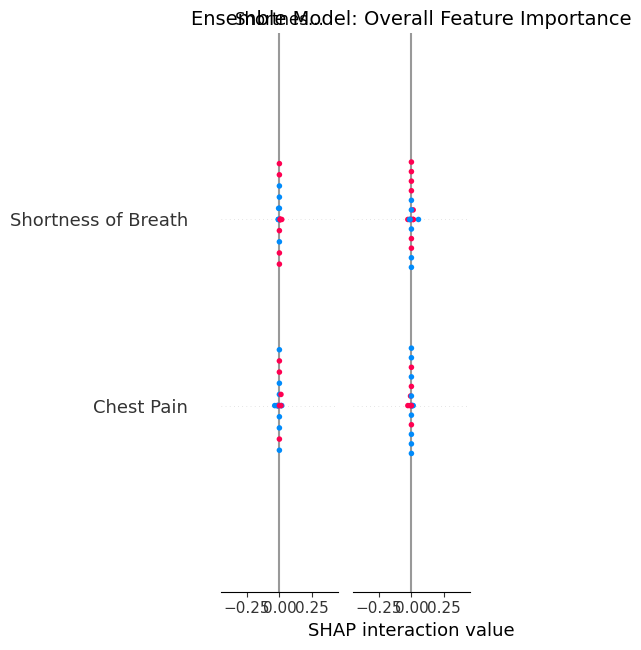

<Figure size 1000x600 with 0 Axes>

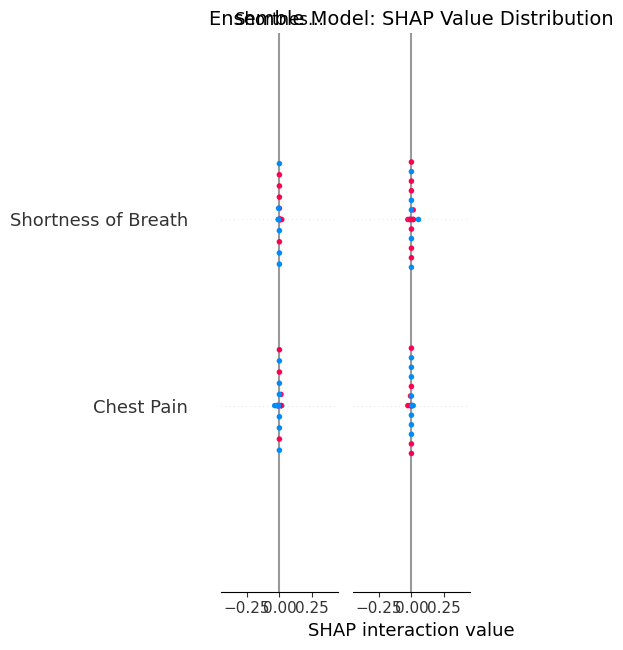


Force plot for first test instance:

SHAP analysis failed: In v0.20, force plot now requires the base value as the first parameter! Try shap.plots.force(explainer.expected_value, shap_values) or for multi-output models try shap.plots.force(explainer.expected_value[0], shap_values[..., 0]).
Possible solutions:
1. Try with n_samples=10
2. Use shap.KernelExplainer(ensemble_model.predict_proba, shap.sample(X_train, 10))
3. Check if your model supports predict_proba
Retrying with minimal configuration...


  0%|          | 0/5 [00:00<?, ?it/s]

Critical error: The shape of the shap_values matrix does not match the shape of the provided data matrix.
Try checking your model's predict_proba output shape


In [45]:
import shap
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

def plot_ensemble_shap(ensemble_model, X_train, X_test, top_models, n_samples=100):
    """
    Optimized SHAP visualization for ensemble models only

    Parameters:
    - ensemble_model: Your trained VotingClassifier
    - X_train: Training data (for background)
    - X_test: Test data to explain
    - top_models: List of model names in ensemble
    - n_samples: Number of samples to use for explanation
    """
    print("\nSHAP Analysis for Ensemble Model Only")
    print(f"Models in ensemble: {top_models}")

    try:
        # 1. Prepare data - use smaller samples
        background = shap.sample(X_train, min(50, len(X_train)))
        explain_data = X_test.sample(min(n_samples, len(X_test)), random_state=42)

        # 2. Select appropriate explainer
        if all(any(x in m.lower() for x in ['tree','forest','boost']) for m in top_models):
            explainer = shap.TreeExplainer(ensemble_model, background)
            print("Using TreeExplainer (fast for tree-based ensembles)")
        else:
            explainer = shap.KernelExplainer(
                ensemble_model.predict_proba,
                background,
                nsamples=100  # Reduced from default 2048
            )
            print("Using KernelExplainer (slower but general-purpose)")

        # 3. Compute SHAP values with progress bar
        print(f"Computing SHAP values for {len(explain_data)} instances...")

        # Correct SHAP values calculation
        shap_values = explainer.shap_values(explain_data)

        # Handle multi-class output
        if isinstance(shap_values, list):
            shap_values = shap_values[1]  # Use values for positive class

        # Get expected value
        if isinstance(explainer.expected_value, list):
            expected_value = explainer.expected_value[1]
        else:
            expected_value = explainer.expected_value

        # 4. Visualizations -------------------------------------------------
        plt.figure(figsize=(10, 6))

        # A. Summary Plot (Bar)
        shap.summary_plot(shap_values, explain_data, plot_type="bar", show=False)
        plt.title("Ensemble Model: Overall Feature Importance", fontsize=14)
        plt.tight_layout()
        plt.show()

        # B. Summary Plot (Beeswarm)
        plt.figure(figsize=(10, 6))
        shap.summary_plot(shap_values, explain_data, show=False)
        plt.title("Ensemble Model: SHAP Value Distribution", fontsize=14)
        plt.tight_layout()
        plt.show()

        # C. Force Plot (First instance)
        print("\nForce plot for first test instance:")
        shap.force_plot(
            expected_value,
            shap_values[0],
            explain_data.iloc[0],
            matplotlib=True
        )
        plt.show()

        return shap_values

    except Exception as e:
        print(f"\nSHAP analysis failed: {str(e)}")
        print("Possible solutions:")
        print("1. Try with n_samples=10")
        print("2. Use shap.KernelExplainer(ensemble_model.predict_proba, shap.sample(X_train, 10))")
        print("3. Check if your model supports predict_proba")
        return None

# Usage with error handling:
try:
    ensemble_shap = plot_ensemble_shap(
        ensemble_model=ensemble_model,
        X_train=X_train,
        X_test=X_test,
        top_models=top_models,
        n_samples=20  # Start with fewer samples
    )

    if ensemble_shap is None:
        print("Retrying with minimal configuration...")
        # Fallback attempt
        explainer = shap.KernelExplainer(
            ensemble_model.predict_proba,
            shap.sample(X_train, 10),
            nsamples=50
        )
        shap_values = explainer.shap_values(X_test.sample(5))
        shap.summary_plot(shap_values[1], X_test.sample(5))

except Exception as e:
    print(f"Critical error: {str(e)}")
    print("Try checking your model's predict_proba output shape")


Explaining instance 5 (True class: 0, Predicted prob: 1.00)


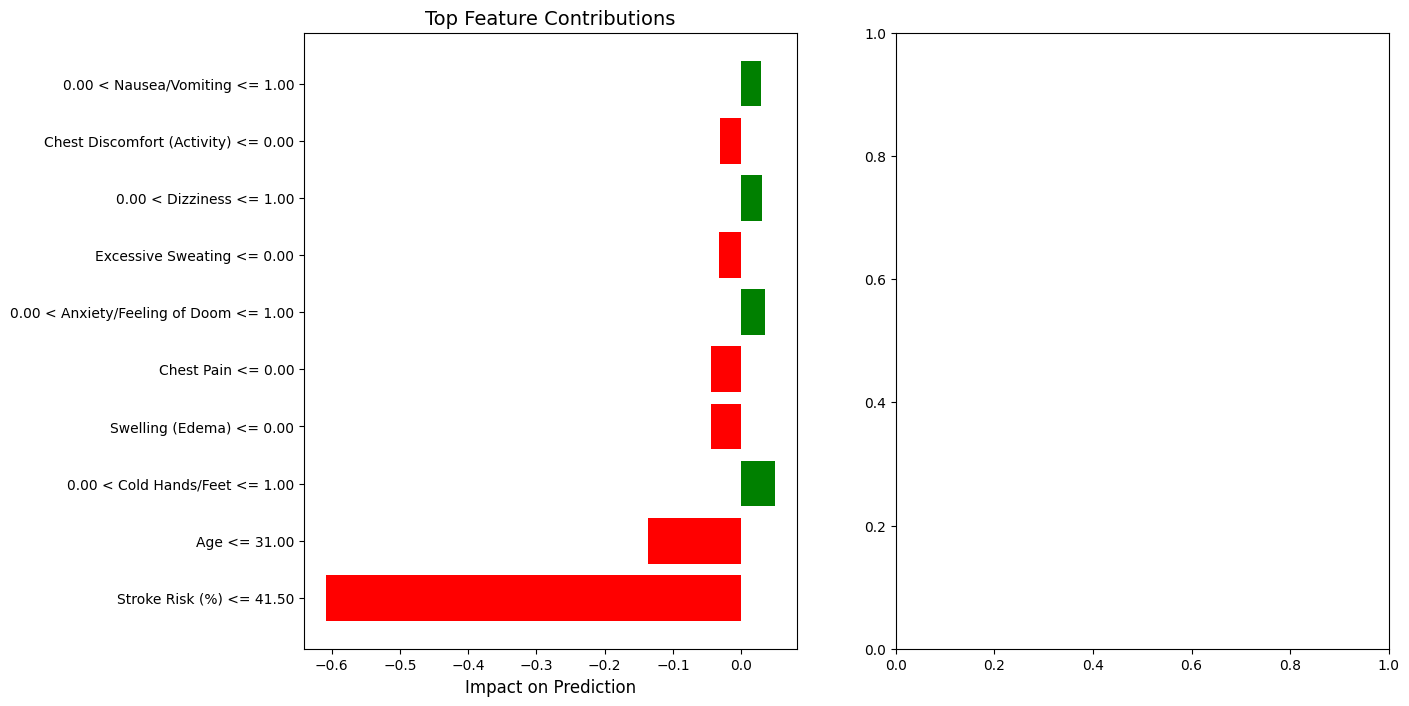

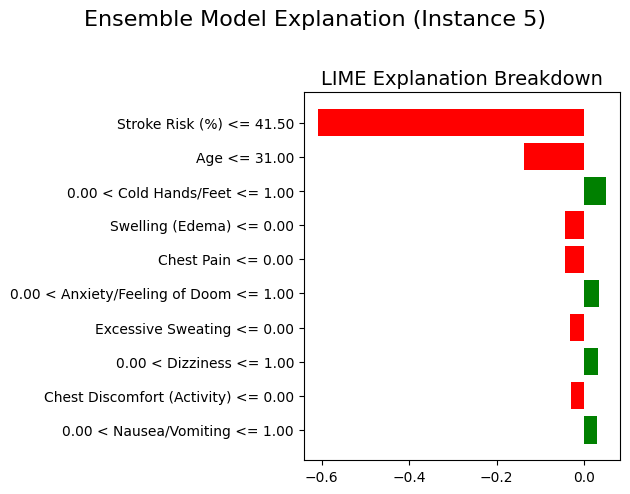

Successfully generated ensemble explanation plot


In [47]:
from lime import lime_tabular
from lime.lime_tabular import LimeTabularExplainer
import matplotlib.pyplot as plt
import numpy as np

def plot_lime_ensemble_explanation(ensemble_model, X_train, X_test, y_test, feature_names=None):
    """
    Generate and plot LIME explanation for ONE representative instance from ensemble model

    Args:
        ensemble_model: Trained VotingClassifier
        X_train: Training features (DataFrame)
        X_test: Test features (DataFrame)
        y_test: Test labels (for verification)
        feature_names: List of feature names to use
    """
    try:
        # Set default feature names if not provided
        feature_names = X_train.columns.tolist() if feature_names is None else feature_names
        X_test_array = X_test[feature_names].values

        # Initialize LIME explainer
        explainer = LimeTabularExplainer(
            training_data=X_train[feature_names].values,
            feature_names=feature_names,
            class_names=['No Stroke', 'Stroke'],
            mode='classification',
            random_state=42
        )

        # Select one representative instance (highest confidence correct prediction)
        pred_probs = ensemble_model.predict_proba(X_test_array)
        confidence = np.max(pred_probs, axis=1)
        correct_preds = (np.argmax(pred_probs, axis=1) == y_test.values)  # Fixed missing parenthesis
        sample_idx = np.argmax(confidence * correct_preds)

        print(f"\nExplaining instance {sample_idx} (True class: {y_test.iloc[sample_idx]}, "
              f"Predicted prob: {np.max(pred_probs[sample_idx]):.2f})")

        # Generate explanation
        exp = explainer.explain_instance(
            X_test_array[sample_idx],
            ensemble_model.predict_proba,
            num_features=10
        )

        # Single comprehensive plot
        plt.figure(figsize=(14, 8))

        # Left subplot - Feature importance
        plt.subplot(1, 2, 1)
        features = [x[0] for x in exp.as_list()]
        impacts = [x[1] for x in exp.as_list()]
        colors = ['green' if x > 0 else 'red' for x in impacts]

        plt.barh(features, impacts, color=colors)
        plt.title('Top Feature Contributions', fontsize=14)
        plt.xlabel('Impact on Prediction', fontsize=12)

        # Right subplot - LIME explanation
        plt.subplot(1, 2, 2)
        exp.as_pyplot_figure()
        plt.title('LIME Explanation Breakdown', fontsize=14)
        plt.gca().set_ylabel('')  # Remove redundant label

        plt.suptitle(f"Ensemble Model Explanation (Instance {sample_idx})", fontsize=16, y=1.02)
        plt.tight_layout()
        plt.show()

        return exp

    except Exception as e:
        print(f"LIME explanation failed: {str(e)}")
        return None

# Example usage
ensemble_exp = plot_lime_ensemble_explanation(
    ensemble_model=ensemble_model,
    X_train=X_train,
    X_test=X_test,
    y_test=y_test
)

if ensemble_exp:
    print("Successfully generated ensemble explanation plot")
else:
    print("Failed to generate explanation")